### Qiskit (Quantum Information Science Kit)

#### Using the simulator

$\bullet~$ create a quantum circuit with registers of qubits and register of bits

In [1]:
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit

qreg = QuantumRegister(1, 'q')
creg = ClassicalRegister(1, 'c')
circuit = QuantumCircuit(qreg, creg)

circuit.x(qreg[0])

circuit.draw()

┌───┐
  q: ┤ X ├
     └───┘
c: 1/═════

$\bullet~$ do a measurement of one or several qubits

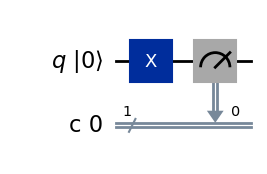

In [2]:
circuit.measure(qreg,creg)

circuit.draw('mpl', initial_state=True)

$\bullet~$ do a QASM (measurement) simulation

In [3]:
from qiskit_aer import Aer

simulator = Aer.get_backend('qasm_simulator')
job = simulator.run(circuit, shots=1000)
counts = job.result().get_counts(circuit)
print("\nTotal counts are:",counts)


Total counts are: {'1': 1000}


$\bullet~$ create a superposition state using a Hadamard gate

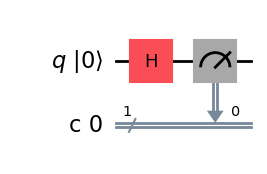

In [4]:
qreg = QuantumRegister(1, 'q')
creg = ClassicalRegister(1, 'c')
circuit = QuantumCircuit(qreg, creg)

circuit.h(qreg[0])

circuit.measure(qreg,creg)

circuit.draw('mpl', initial_state=True)

$\bullet~$ do a QASM (measurement) simulation

In [5]:
simulator = Aer.get_backend('qasm_simulator')
job = simulator.run(circuit, shots=1000)
counts = job.result().get_counts(circuit)
print("\nTotal counts are:",counts)


Total counts are: {'0': 504, '1': 496}


$\bullet~$ plot the measurement results in a histogram

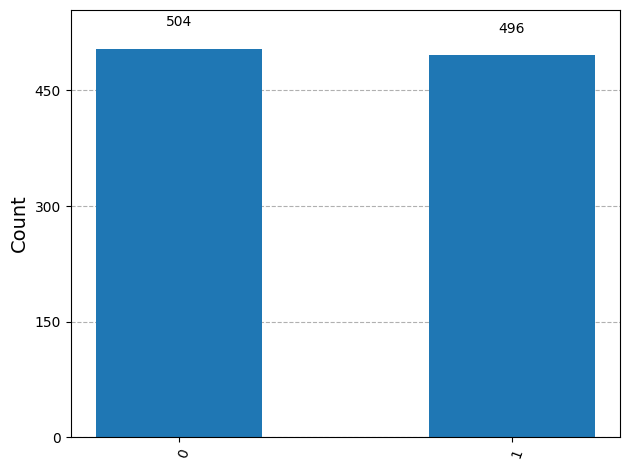

In [6]:
from qiskit.visualization import plot_histogram

plot_histogram(counts)

$\bullet~$ simulate the projection of the statevector after the measurement

In [7]:
simulator = Aer.get_backend('statevector_simulator')
job = simulator.run(circuit)
psi = job.result().get_statevector(circuit)
print(psi)

Statevector([1.+0.j, 0.+0.j],
            dims=(2,))


In [8]:
from qiskit.visualization import array_to_latex

array_to_latex(psi, prefix="| \\psi \\rangle = ")

<IPython.core.display.Latex object>

In [9]:
print(array_to_latex(psi, prefix="| \\psi \\rangle = ", source=True))


| \psi \rangle = 
\begin{bmatrix}
1 & 0  \\
 \end{bmatrix}



$\bullet~$ visualize on the Bloch sphere

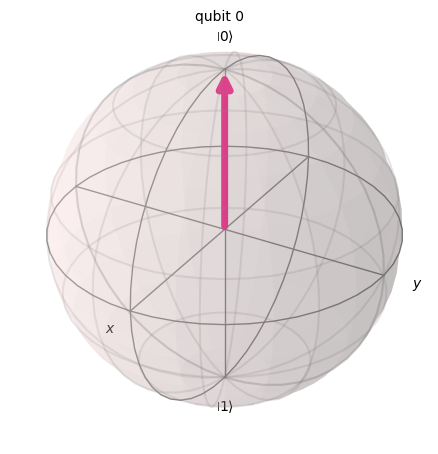

In [10]:
from qiskit.visualization import plot_bloch_multivector

plot_bloch_multivector(psi)

$\bullet~$ a rotation aroung the x-axis $~R_{x}(\pi / 2)~$, but without a measurement at the end!

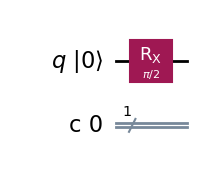

In [11]:
from numpy import pi

qreg = QuantumRegister(1, 'q')
creg = ClassicalRegister(1, 'c')
circuit = QuantumCircuit(qreg, creg)

circuit.rx(pi/2, qreg[0])

circuit.draw('mpl', initial_state=True)

$\bullet~$ simulate and extract the unitary operator representing the circuit action

In [12]:
from qiskit.compiler import transpile

simulator = Aer.get_backend('unitary_simulator')
job = simulator.run(transpile(circuit, simulator))
unitary = job.result().get_unitary(circuit, decimals=3)
array_to_latex(unitary, prefix="\\text{U} = ")

<IPython.core.display.Latex object>

$\bullet~$ simulate the transformation of the statevector

In [13]:
simulator = Aer.get_backend('statevector_simulator')
job = simulator.run(circuit)
psi = job.result().get_statevector(circuit)
array_to_latex(psi, prefix="| \\psi \\rangle = ")

<IPython.core.display.Latex object>

$\bullet~$ the Qiskit-special **qsphere** plot

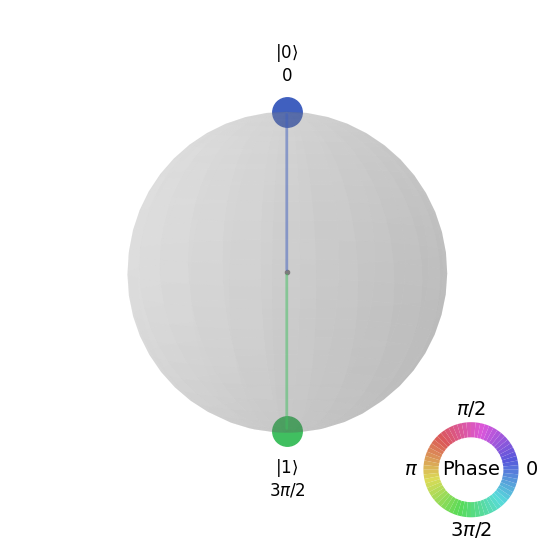

In [14]:
from qiskit.visualization import plot_state_qsphere

plot_state_qsphere(psi, show_state_phases=True)

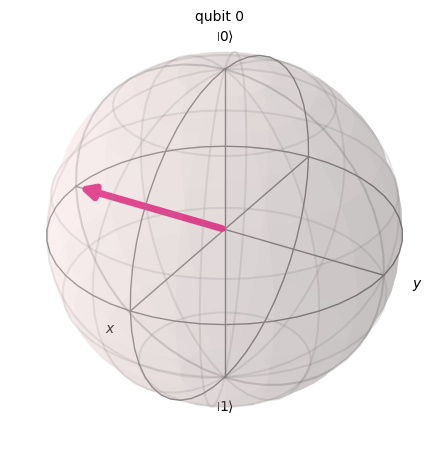

In [15]:
plot_bloch_multivector(psi)

$\bullet~$ another rotation, equivalent to the Hadamard gate: $~H = R_{y}(\pi/2)$

In [16]:
qreg = QuantumRegister(1, 'q')
creg = ClassicalRegister(1, 'c')
circuit = QuantumCircuit(qreg, creg)

circuit.h(qreg[0])

simulator = Aer.get_backend('statevector_simulator')
job = simulator.run(circuit)
psi = job.result().get_statevector(circuit)
array_to_latex(psi, prefix="| \\psi \\rangle = ")

<IPython.core.display.Latex object>

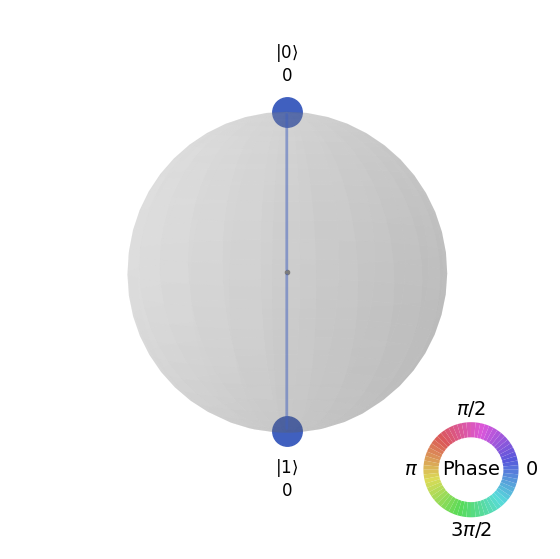

In [17]:
plot_state_qsphere(psi, show_state_phases=True)

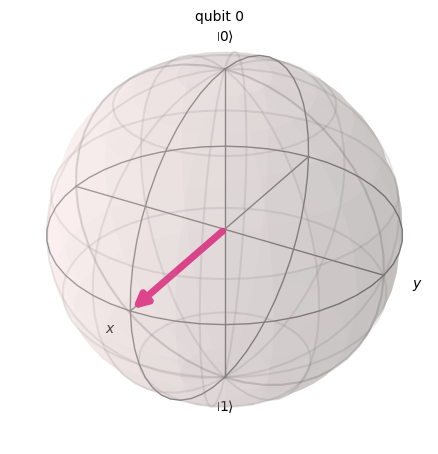

In [18]:
plot_bloch_multivector(psi)

$\bullet~$ a 2-qubit gate: CNOT

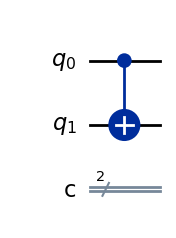

In [19]:
qreg = QuantumRegister(2, 'q')
creg = ClassicalRegister(2, 'c')
circuit = QuantumCircuit(qreg, creg)

circuit.cx(qreg[0], qreg[1])

circuit.draw('mpl')

$\bullet~$ simulate the unitary operator

In [20]:
simulator = Aer.get_backend('unitary_simulator')
job = simulator.run(transpile(circuit, simulator))
unitary = job.result().get_unitary(circuit, decimals=3)
array_to_latex(unitary, prefix="\\text{U} = ")

<IPython.core.display.Latex object>

$\bullet~$ example of using the **transpile** compilation

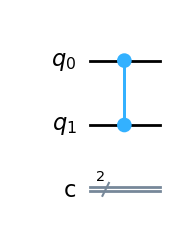

In [21]:
qreg = QuantumRegister(2, 'q')
creg = ClassicalRegister(2, 'c')
circuit = QuantumCircuit(qreg, creg)

circuit.cz(qreg[0], qreg[1])

circuit.draw('mpl')

$\bullet~$ transpile with only CX and H gates

/home/vulpescu/qiskit-2.2.0/lib/python3.9/site-packages/qiskit/compiler/transpiler.py:269: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  pm = generate_preset_pass_manager(


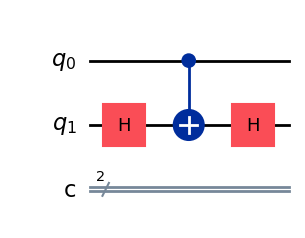

In [22]:
simulator = Aer.get_backend('qasm_simulator')
circuit_t = transpile(circuit, simulator, basis_gates=['cx','h'])

circuit_t.draw('mpl')

$\bullet~$ get the operator from the circuit

In [23]:
from qiskit import quantum_info as qi

op = qi.Operator.from_circuit(circuit)
array_to_latex(op, prefix="\\text{O} = ")

<IPython.core.display.Latex object>

$\bullet~$ import a QASM code (a Bell state)

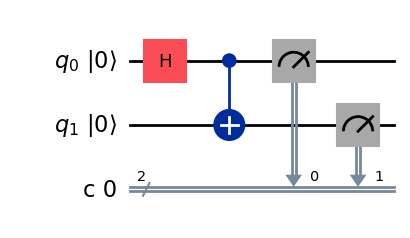

In [24]:
qasm = """OPENQASM 2.0;
include "qelib1.inc";

qreg q[2];
creg c[2];
h q[0];
cx q[0], q[1];
measure q[0] -> c[0];
measure q[1] -> c[1];
"""

circuit = QuantumCircuit.from_qasm_str(qasm)
circuit.draw('mpl', initial_state=True)

#### Using a simulator, without and with quantum noise

$\bullet~$ transpile the circuit for a **generic backend**; if `basis_gates` is `None`, the default are ` ['id', 'rz', 'sx', 'x', 'cx']`; if `noise_info=True` it associates gates and qubits with some default noise

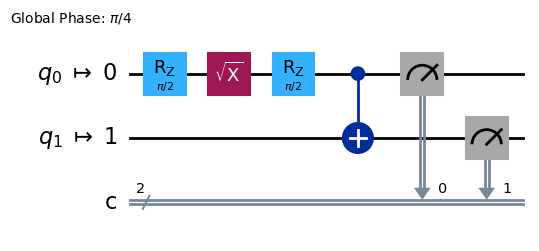

In [25]:
from qiskit.providers.fake_provider import GenericBackendV2

backend = GenericBackendV2(num_qubits=2, basis_gates=None, noise_info=True)
circuit = QuantumCircuit.from_qasm_str(qasm)
circuit_t = transpile(circuit, backend)

circuit_t.draw('mpl')

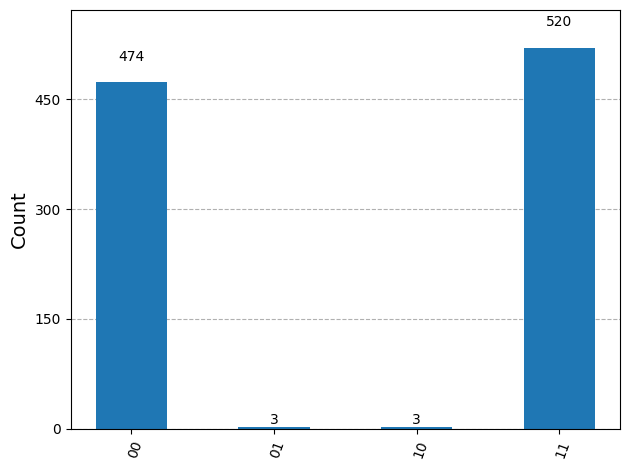

In [26]:
job = backend.run(circuit_t, shots=1000)
counts = job.result().get_counts(circuit_t)
plot_histogram(counts)

$\bullet~$ use a **fake backend**, which implements noise inspired by the real device

note: IBM quantum processors were given names of big cities all around the world, for instance `Manila` (it was a QPU with only 5 qubits)

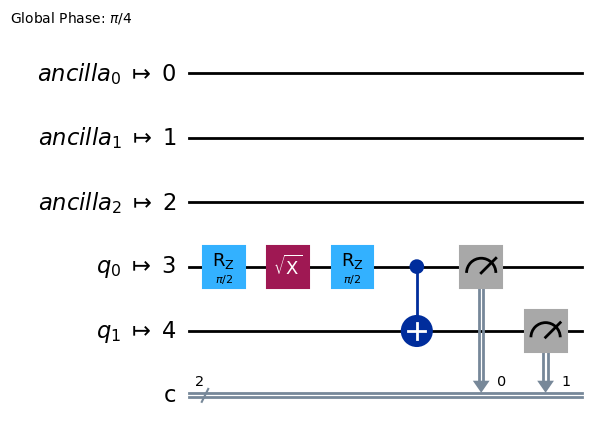

In [27]:
from qiskit_ibm_runtime.fake_provider import FakeManilaV2
backend = FakeManilaV2()
circuit = QuantumCircuit.from_qasm_str(qasm)
circuit_t = transpile(circuit, backend)

circuit_t.draw('mpl', idle_wires=True)

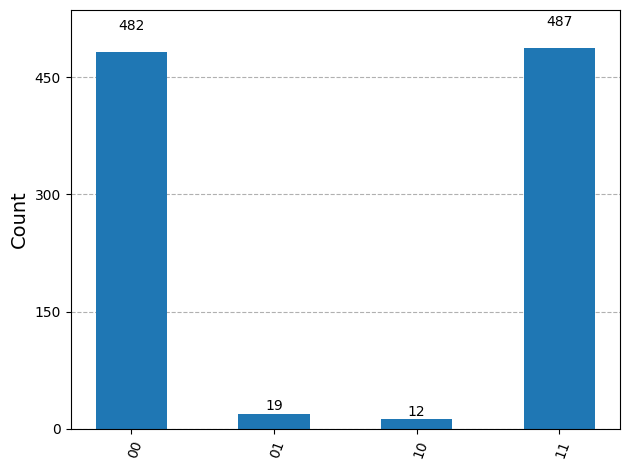

In [28]:
job = backend.run(circuit_t, shots=1000)
counts = job.result().get_counts(circuit_t)
plot_histogram(counts)

$\Rightarrow~$ note that the noise is higher than what was estimated in the generic backend

#### Using the IBM runtime (only with IBM account, optional)

`https://docs.quantum.ibm.com/api/qiskit-ibm-runtime/qiskit_ibm_runtime.IBMBackend`

In [29]:
#from qiskit_ibm_runtime import QiskitRuntimeService
#service = QiskitRuntimeService()
#print(service.backends())

$\bullet~$ select a backend

In [30]:
#backend = service.backend("ibm_brisbane")
#backend.status()

In [31]:
#print(
#    f"Name: {backend.name}\n"
#    f"Version: {backend.version}\n"
#    f"No. of qubits: {backend.num_qubits}\n"
#)

In [32]:
#backend.qubit_properties(0)

$\bullet~$ transpile the circuit using only the basis gates available on the selected backend

In [33]:
#bg = backend.basis_gates
#bg

In [34]:
#circuit_t = transpile(circuit, simulator, basis_gates=bg)
#circuit_t.draw('mpl')

#### (end of the optional section)

#### A universal unitary operator: $~~U(\theta, \phi, \lambda) = 
\begin{pmatrix}
\cos(\frac{\theta}{2}) & - e^{i \lambda} \sin(\frac{\theta}{2}) \\
e^{i \phi} \sin(\frac{\theta}{2}) & e^{i (\phi + \lambda)} \cos(\frac{\theta}{2})
\end{pmatrix}$

(see **Math_02**)

$\bullet~$ example: $~X = U(\pi, 0, \pi)$

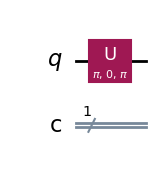

In [35]:
import numpy as np

qreg = QuantumRegister(1, 'q')
creg = ClassicalRegister(1, 'c')
qc = QuantumCircuit(qreg, creg)

qc.u(np.pi, 0, np.pi, qreg[0])

qc.draw('mpl')

In [36]:
simulator = Aer.get_backend('statevector_simulator')
job = simulator.run(qc)
psi = job.result().get_statevector(qc)
array_to_latex(psi, prefix="| \\psi \\rangle = ")

<IPython.core.display.Latex object>

$\bullet~$ parametrized circuits

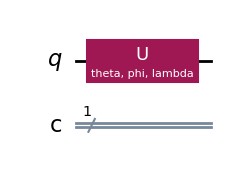

In [37]:
from qiskit.circuit import Parameter

th_par = Parameter("theta")
ph_par = Parameter("phi")
la_par = Parameter("lambda")

qreg = QuantumRegister(1, 'q')
creg = ClassicalRegister(1, 'c')
qc = QuantumCircuit(qreg, creg)

qc.u(th_par, ph_par, la_par, qreg[0])

qc.draw('mpl')

$\bullet~$ transpile this parametrized circuit for a **generic backend**, taking care to $eliminate$ the `cx` gate from the basis gates, because this one requires 2 qubits and here we have only one qubit

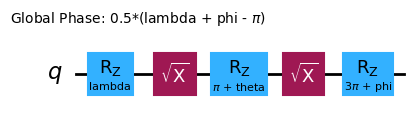

In [38]:
backend = GenericBackendV2(num_qubits=1, basis_gates=["id", "rz", "sx", "x"], noise_info=False)
qc_t = transpile(qc, backend)
qc_t.draw('mpl')

$\Rightarrow~$ check if this is true!

$\bullet~$ to the original, not transpiled circuit, assign values to parameters; modify the circuit itself with `inplace=True`

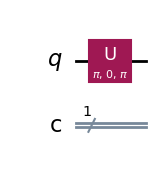

In [39]:
qc.assign_parameters({th_par:np.pi, ph_par:0, la_par:np.pi}, inplace=True)
qc.draw('mpl')

#### Qiskit version

In [41]:
import tutorial_magics

%qiskit_version_table
%qiskit_copyright